In [10]:
%pip install -U langchain-huggingface sentence-transformers faiss-cpu

     ---------------------------------------- 0.0/740.6 kB ? eta -:--:--
     --------------- ---------------------- 307.2/740.6 kB 9.6 MB/s eta 0:00:01
     --------------------------------- ---- 645.1/740.6 kB 6.8 MB/s eta 0:00:01
     -------------------------------------- 740.6/740.6 kB 5.8 MB/s eta 0:00:00
     ---------------------------------------- 0.0/16.3 MB ? eta -:--:--
     - -------------------------------------- 0.5/16.3 MB 15.0 MB/s eta 0:00:02
     - -------------------------------------- 0.7/16.3 MB 7.3 MB/s eta 0:00:03
     -- ------------------------------------- 0.8/16.3 MB 6.7 MB/s eta 0:00:03
     -- ------------------------------------- 1.0/16.3 MB 5.7 MB/s eta 0:00:03
     --- ------------------------------------ 1.2/16.3 MB 5.6 MB/s eta 0:00:03
     --- ------------------------------------ 1.4/16.3 MB 5.3 MB/s eta 0:00:03
     --- ------------------------------------ 1.6/16.3 MB 5.0 MB/s eta 0:00:03
     ---- ----------------------------------- 1.7/16.3 MB 4.8

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langchain-text-splitters 0.3.0 requires langchain-core<0.4.0,>=0.3.0, but you have langchain-core 1.6.9 which is incompatible.
langchain-community 0.4.2 requires requests<3.0.0,>=2.32.5, but you have requests 2.32.3 which is incompatible.
langchain-classic 1.0.8 requires langchain-text-splitters<2.0.0,>=1.1.2, but you have langchain-text-splitters 0.3.0 which is incompatible.

[notice] A new release of pip is available: 23.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
from typing import List, TypedDict

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_huggingface.embeddings import HuggingFaceEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv

load_dotenv()

True

In [5]:
docs = (
    PyPDFLoader("./documents/book1.pdf").load() +
    PyPDFLoader("./documents/book2.pdf").load() +
    PyPDFLoader("./documents/book3.pdf").load()
)

In [6]:
len(docs)

2123

In [12]:
# 2) Chunk
chunks = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=150).split_documents(docs)

# 3) Clean text to avoid UnicodeEncodeError (surrogates from PDF extraction)
for d in chunks:
    d.page_content = d.page_content.encode("utf-8", "ignore").decode("utf-8", "ignore")

In [13]:
len(chunks)

6393

In [14]:
# 3) Index (fresh collection each run)
embeddings = HuggingFaceEmbeddings(model="sentence-transformers/all-MiniLM-L6-v2")
vector_store = FAISS.from_documents(chunks, embeddings)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [15]:
retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k':4})

In [16]:
# 4) LLM + prompt
llm = ChatGoogleGenerativeAI(model="gemini-2.5-flash-lite", temperature=0)

Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


In [17]:
class State(TypedDict):
    question: str
    docs: List[Document]
    answer: str

In [18]:
def retrieve(state):
    q = state["question"]
    return {"docs": retriever.invoke(q)}

In [19]:

prompt = ChatPromptTemplate.from_messages(
    [
        ("system", "Answer only from the context. If not in context, say you don't know."),
        ("human", "Question: {question}\n\nContext:\n{context}"),
    ]
)
def generate(state):
    context = "\n\n".join(d.page_content for d in state["docs"])
    out = (prompt | llm).invoke({"question": state["question"], "context": context})
    return {"answer": out.content}


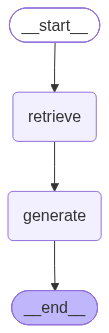

In [20]:
g = StateGraph(State)
g.add_node("retrieve", retrieve)
g.add_node("generate", generate)
g.add_edge(START, "retrieve")
g.add_edge("retrieve", "generate")
g.add_edge("generate", END)
app = g.compile()

app

In [24]:
# 5) Run
res = app.invoke({"question": "What is the transformer achitecture.", "docs": [], "answer": ""})
print(res["answer"])

The context does not define what a transformer architecture is. It describes transformers as estimators that can transform a dataset using a `transform()` method, and mentions that custom transformers can be created by implementing `fit()`, `transform()`, and `fit_transform()` methods.


In [25]:
print(res['docs'][0].page_content)
print('*'*100)
print(res['docs'][1].page_content)
print('*'*100)
print(res['docs'][2].page_content)
print('*'*100)
print(res['docs'][3].page_content)

All transformers also have a convenience method called fit_transform() 
Prepare the Data for Machine Learning Algorithms | 61
 D o w n l o a d   f r o m   f i n e l y b o o k   w w w . f i n e l y b o o k . c o m
****************************************************************************************************
performed by the fit() method, and it takes only a dataset as a parameter (or
two for supervised learning algorithms; the second dataset contains the
labels). Any other parameter needed to guide the estimation process is con‐
sidered a hyperparameter (such as an imputer’s strategy), and it must be set
as an instance variable (generally via a constructor parameter).
— Transformers. Some estimators (such as an imputer ) can also transform a
dataset; these are called transformers. Once again, the API is quite simple: the
transformation is performed by the transform() method with the dataset to
transform as a parameter. It returns the transformed dataset. This transforma‐
tion gene